# 05 · Sur-cotés et sous-cotés

Certains Pokémon sont populaires « pour des raisons évidentes » : c'est un starter, un légendaire, il vient de la première génération (nostalgie)… L'idée de ce notebook, c'est de **retirer ces effets attendus** pour voir ce qui reste.

Méthode : une **régression linéaire** (hors cours) de la popularité sur les effets attendus. Pour chaque Pokémon, le modèle donne une popularité « prévue ». Le **résidu** = popularité réelle − popularité prévue :
- résidu positif → le Pokémon est **plus populaire que prévu** (sur-coté) ;
- résidu négatif → **moins populaire que prévu** (sous-coté).

Comme on ne fusionne pas les sources (notebook 01), on fait **une régression par source** (Reddit, Johto Times, Google Trends) et on compare les résidus. Un Pokémon qui est sur-coté dans les trois sources, c'est beaucoup plus solide qu'un Pokémon sur-coté chez un seul public.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)
OUT = Path("../data/processed")
table = pd.read_csv(OUT / "table_maitre.csv", index_col="dex")
pop = pd.read_csv(OUT / "popularite_sources.csv", index_col="dex")
df = table.join(pop.drop(columns=["nom_fr", "generation"]))
df.shape

(1025, 47)

## 1. Quelle popularité expliquer ?

Pour chaque source on prend le **percentile** (décision du notebook 01) :
- **Reddit** : percentile global (809 Pokémon). Comme c'est global, on peut mettre la génération dans le modèle ;
- **Johto Times** : percentile **dans la génération**. Par construction, toutes les générations ont la même moyenne : l'effet génération est déjà retiré, on ne peut pas le mettre dans le modèle ;
- **Google Trends** : percentile médian sur les 67 pays gardés, sur tous les Pokémon (global). Attention, les 17 noms ambigus repérés dans le notebook 02 (Persian, Fermite…) ont des valeurs Google gonflées.

In [2]:
df["y_reddit"] = df["reddit_pct"]
df["y_johto"] = df["johto_pct_gen"]
df["y_trends"] = df["trends_pct_median"]
df[["y_reddit", "y_johto", "y_trends"]].describe()

,y_reddit,y_johto,y_trends
count,809.000000,1025.000000,1025.000000
mean,0.500618,0.504390,0.500431
std,0.288797,0.288802,0.278957
min,0.003090,0.006410,0.027805
25%,0.254017,0.253205,0.256098
50%,0.493820,0.503704,0.500000
75%,0.749691,0.754967,0.739024
max,1.000000,1.000000,0.999024


Les trois percentiles vont de 0 à 1 avec une moyenne de 0,5, c'est normal pour des percentiles. Reddit n'a que 809 Pokémon.

## 2. Les effets attendus

On regarde d'abord chaque effet séparément, pour chaque source.

In [3]:
df["type_principal"] = df["type1"]
effets = ["generation", "stade_categorie", "starter", "legendaire", "fabuleux", "type_principal"]
for e in effets:
    print(df.groupby(e)[["y_reddit", "y_johto", "y_trends"]].mean().round(2).assign(n=df[e].value_counts()), "\n")

            y_reddit  y_johto  y_trends    n
generation                                  
1               0.67     0.50      0.74  151
2               0.62     0.51      0.57  100
3               0.51     0.50      0.52  135
4               0.54     0.50      0.55  107
5               0.37     0.50      0.40  156
6               0.41     0.51      0.50   72
7               0.32     0.51      0.45   88
8                NaN     0.51      0.39   96
9                NaN     0.50      0.34  120 

                 y_reddit  y_johto  y_trends    n
stade_categorie                                  
sans évolution       0.50     0.55      0.56  201
stade 1              0.41     0.39      0.52  340
stade 2              0.51     0.49      0.40  363
stade 3              0.72     0.79      0.63  121 

         y_reddit  y_johto  y_trends    n
starter                                  
False        0.48     0.49      0.49  944
True         0.70     0.70      0.60   81 

            y_reddit  y_johto  

Ce qu'on voit effet par effet :
- **génération** : sur Reddit et Google Trends, la génération 1 est nettement au-dessus et les générations récentes en dessous. C'est l'effet nostalgie qu'on attendait. Le Johto Times est à 0,5 partout, normal puisque c'est un percentile dans la génération ;
- **stade** : le stade 3 est le plus aimé dans les trois sources ;
- **starters** : 0,70 dans les deux sondages contre 0,48-0,49 pour les autres ;
- **légendaires** : ils sont **moins** bien classés que la moyenne sur Reddit (0,45), mais mieux au Johto Times (0,63) et sur Google ;
- **type** : Ténèbres, Spectre et Dragon sont en haut dans les sondages, Insecte et Roche en bas.

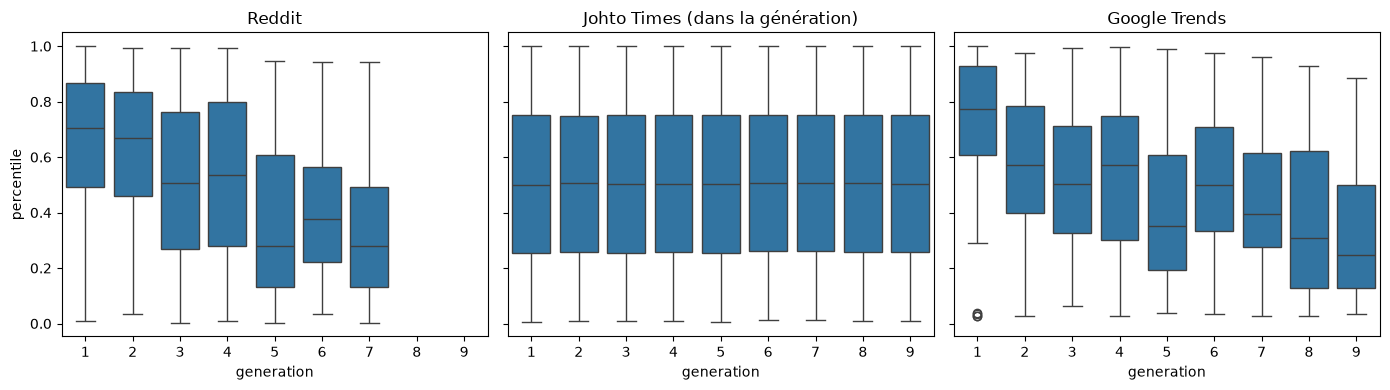

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, y, titre in zip(axes, ["y_reddit", "y_johto", "y_trends"], ["Reddit", "Johto Times (dans la génération)", "Google Trends"]):
    sns.boxplot(data=df, x="generation", y=y, ax=ax)
    ax.set_title(titre)
    ax.set_ylabel("percentile")
plt.tight_layout()
plt.show()

## 3. Les régressions

On choisit comme variables explicatives les **effets « évidents »** qu'on retrouve dans l'axe ② du projet : génération (sauf pour le Johto Times, où elle est déjà retirée), catégorie de stade, starter, légendaire, fabuleux et type principal. On ne met volontairement **pas** le design (stats, taille, couleurs) : c'est justement ce qu'on veut retrouver dans ce qui reste.

Les variables qualitatives sont transformées en indicatrices (`C(...)`) avec une modalité de référence (génération 1, stade 1, type Normal). On utilise des erreurs standard robustes (HC3), parce que rien ne dit que la variance est la même pour tous les groupes.

In [5]:
base = "C(stade_categorie, Treatment('stade 1')) + starter + legendaire + fabuleux + C(type_principal, Treatment('normal'))"
formules = {
    "reddit": "y_reddit ~ C(generation) + " + base,
    "johto": "y_johto ~ " + base,
    "trends": "y_trends ~ C(generation) + " + base,
}
# Reddit ne couvre pas les générations 8 et 9 : on ne garde que les Pokémon qui ont une valeur dans la source
modeles = {s: smf.ols(f, data=df[df[f"y_{s}"].notna()]).fit(cov_type="HC3") for s, f in formules.items()}
pd.DataFrame({s: {"n": int(m.nobs), "R2": m.rsquared, "R2_ajuste": m.rsquared_adj} for s, m in modeles.items()}).round(3)

,reddit,johto,trends
n,809.000,1025.000,1025.000
R2,0.379,0.256,0.399
R2_ajuste,0.356,0.239,0.380


Ce premier modèle explique environ **36 % de la variance sur Reddit, 24 % au Johto Times et 38 % sur Google Trends** (R² ajusté). Le Johto Times est plus bas en partie parce que l'effet génération n'est pas dans le modèle. Il reste donc la majorité de la popularité qui n'est pas expliquée par ces effets.

In [6]:
# les coefficients côte à côte (en points de percentile), avec une étoile si p < 0,05
def tab(m):
    return m.params.round(3).astype(str) + np.where(m.pvalues < 0.05, " *", "")
coefs = pd.DataFrame({s: tab(m) for s, m in modeles.items()})
coefs.index = coefs.index.str.replace("C(stade_categorie, Treatment('stade 1'))", "stade").str.replace("C(type_principal, Treatment('normal'))", "type").str.replace("C(generation)", "gen")
coefs.fillna("")

,reddit,johto,trends
gen[T.2],-0.056,,-0.184 *
gen[T.3],-0.183 *,,-0.247 *
gen[T.4],-0.17 *,,-0.229 *
gen[T.5],-0.338 *,,-0.373 *
gen[T.6],-0.299 *,,-0.3 *
gen[T.7],-0.381 *,,-0.346 *
gen[T.8],,,-0.415 *
gen[T.9],,,-0.451 *
stade[T.sans évolution],0.167 *,0.096 *,-0.007
stade[T.stade 2],0.1 *,0.104 *,-0.12 *


À autres effets égaux (en points de percentile) :
- chaque génération après la première fait perdre entre 6 et 45 points, de plus en plus pour les générations récentes ;
- le stade 3 fait gagner 28 points sur Reddit et 37 au Johto Times, mais seulement 8 sur Google ;
- être starter fait gagner 14 à 23 points ;
- être légendaire fait **perdre** 9 points sur Reddit, mais gagner 13 au Johto Times et 19 sur Google : les deux sondages ne sont pas d'accord sur les légendaires ;
- Ténèbres, Spectre, Dragon et Électrik sont significativement au-dessus de Normal dans les trois sources.

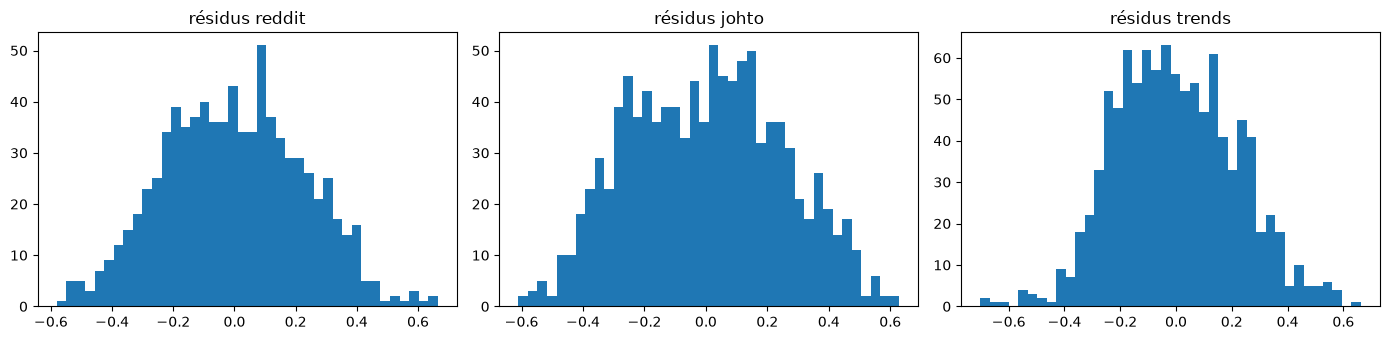

In [7]:
# les résidus : est-ce qu'ils ont l'air normaux ? (sinon les p-valeurs sont à prendre avec des pincettes)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (s, m) in zip(axes, modeles.items()):
    ax.hist(m.resid, bins=40)
    ax.set_title(f"résidus {s}")
plt.tight_layout()
plt.show()

### Le bonus starter est-il le même à tous les stades ?

Le modèle donne le même bonus « starter » à toute la lignée. Mais en pratique, on a l'impression que les fans aiment surtout le petit du début et la forme finale. On regarde la popularité moyenne des starters par stade.

In [8]:
df[df.starter].groupby("stade")[["y_reddit", "y_johto", "y_trends"]].mean().round(2)

,y_reddit,y_johto,y_trends
stade,,,
1,0.78,0.81,0.78
2,0.46,0.39,0.23
3,0.86,0.91,0.78


C'est très net : les starters de stade 1 sont autour de 0,8 et ceux de stade 3 entre 0,78 et 0,91, mais ceux de **stade 2 tombent entre 0,23 et 0,46**. L'étape du milieu est beaucoup moins aimée.

On essaie donc un modèle avec **un effet starter différent pour chaque stade** (une indicatrice starter × stade 1, starter × stade 2, starter × stade 3), et on compare.

In [9]:
for k in [1, 2, 3]:
    df[f"starter_s{k}"] = df["starter"] & (df["stade"] == k)
formules_inter = {s: f.replace("+ starter +", "+ starter_s1 + starter_s2 + starter_s3 +") for s, f in formules.items()}
modeles_inter = {s: smf.ols(f, data=df[df[f"y_{s}"].notna()]).fit(cov_type="HC3") for s, f in formules_inter.items()}
display(pd.DataFrame({s: {"R2 ajusté (un seul effet starter)": modeles[s].rsquared_adj, "R2 ajusté (effet starter par stade)": m.rsquared_adj}
                      for s, m in modeles_inter.items()}).round(3))
display(pd.DataFrame({s: tab(m).filter(like="starter") for s, m in modeles_inter.items()}))

,reddit,johto,trends
R2 ajusté (un seul effet starter),0.356,0.239,0.380
R2 ajusté (effet starter par stade),0.385,0.286,0.418


,reddit,johto,trends
starter_s1[T.True],0.454 *,0.473 *,0.325 *
starter_s2[T.True],-0.004,-0.097,-0.136 *
starter_s3[T.True],0.235 *,0.17 *,0.249 *


Avec un effet starter par stade, le R² ajusté monte dans les trois sources (de 0,239 à 0,286 au Johto Times par exemple). Un starter de stade 1 gagne 33 à 47 points, un starter de stade 3 gagne 17 à 25 points, et un starter de stade 2 ne gagne rien (il perd même 14 points sur Google).

**On garde donc ce deuxième modèle pour calculer les résidus.** Avec le premier, les starters de stade 2 seraient sortis « sous-cotés » juste parce que le modèle leur donnait à tort le même bonus qu'à toute la lignée. Ça aurait été un défaut du modèle, pas un vrai résultat.

## 4. Les résidus : qui est sur-coté, qui est sous-coté ?

In [10]:
res = pd.DataFrame({f"resid_{s}": m.resid for s, m in modeles_inter.items()})
res = df[["nom_fr", "generation", "type1", "stade_categorie", "starter", "legendaire"]].join(res)
res[["resid_reddit", "resid_johto", "resid_trends"]].corr(method="spearman").round(2)

,resid_reddit,resid_johto,resid_trends
resid_reddit,1.00,0.82,0.54
resid_johto,0.82,1.00,0.57
resid_trends,0.54,0.57,1.00


Les résidus des deux sondages se ressemblent beaucoup (0,82) : ce qui reste après avoir retiré les effets attendus est à peu près le même chez les deux publics. Google Trends suit moins (0,54-0,57).

In [11]:
cols = ["nom_fr", "generation", "type1", "stade_categorie", "resid_reddit", "resid_johto", "resid_trends"]
for s in ["reddit", "johto", "trends"]:
    print(f"=== {s} : les plus sur-cotés")
    display(res.sort_values(f"resid_{s}", ascending=False)[cols].head(10).round(2))
    print(f"=== {s} : les plus sous-cotés")
    display(res.sort_values(f"resid_{s}")[cols].head(10).round(2))

=== reddit : les plus sur-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
637,Pyrax,5,bug,stade 2,0.65,0.54,0.52
595,Statitik,5,bug,stade 1,0.63,0.58,0.24
700,Nymphali,6,fairy,stade 2,0.63,0.45,0.55
547,Farfaduvet,5,grass,stade 2,0.57,0.42,0.28
745,Lougaroc,7,rock,stade 2,0.57,0.52,0.56
596,Mygavolt,5,bug,stade 2,0.56,0.42,0.11
768,Sarmuraï,7,bug,stade 2,0.54,0.48,0.42
448,Lucario,4,fighting,stade 2,0.52,0.53,0.47
568,Miamiasme,5,poison,stade 1,0.51,0.35,-0.04


=== reddit : les plus sous-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
267,Charmillon,3,bug,stade 3,-0.58,-0.26,-0.21
247,Ymphect,2,rock,stade 2,-0.55,-0.43,0.03
489,Phione,4,water,sans évolution,-0.55,-0.56,-0.30
188,Floravol,2,grass,stade 2,-0.54,-0.37,-0.36
21,Piafabec,1,normal,stade 1,-0.52,-0.29,-0.18
102,Noeunoeuf,1,grass,stade 1,-0.51,-0.30,-0.20
372,Drackhaus,3,dragon,stade 2,-0.51,-0.54,-0.29
30,Nidorina,1,poison,stade 2,-0.50,-0.26,-0.24
118,Poissirène,1,water,stade 1,-0.50,-0.31,-0.20


=== johto : les plus sur-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
872,Frissonille,8,ice,stade 1,NaN,0.65,0.52
133,Évoli,1,normal,stade 1,0.44,0.65,0.27
194,Axoloto,2,water,stade 1,0.38,0.62,0.35
831,Moumouton,8,normal,stade 1,NaN,0.60,0.26
595,Statitik,5,bug,stade 1,0.63,0.58,0.24
363,Obalie,3,ice,stade 1,0.43,0.58,0.12
123,Insécateur,1,bug,stade 1,0.47,0.55,0.23
637,Pyrax,5,bug,stade 2,0.65,0.54,0.52
448,Lucario,4,fighting,stade 2,0.52,0.53,0.47


... (2 outputs left out)

=== trends : les plus sur-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
632,Fermite,5,bug,sans évolution,-0.00,-0.16,0.66
937,Malvalame,9,fire,stade 2,NaN,0.47,0.57
745,Lougaroc,7,rock,stade 2,0.57,0.52,0.56
571,Zoroark,5,dark,stade 2,0.32,0.39,0.55
700,Nymphali,6,fairy,stade 2,0.63,0.45,0.55
900,Hachécateur,8,bug,stade 2,NaN,0.18,0.54
637,Pyrax,5,bug,stade 2,0.65,0.54,0.52
600,Clic,5,steel,stade 2,-0.32,-0.42,0.52
428,Lockpin,4,normal,stade 2,0.29,0.27,0.52


=== trends : les plus sous-cotés


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
29,Nidoran♀,1,poison,stade 1,-0.34,-0.13,-0.69
32,Nidoran♂,1,poison,stade 1,-0.13,-0.12,-0.69
122,M. Mime,1,psychic,stade 2,0.05,-0.13,-0.66
28,Sablaireau,1,ground,stade 2,0.14,0.26,-0.64
1001,Chongjian,9,dark,sans évolution,NaN,-0.20,-0.54
1003,Dinglu,9,dark,sans évolution,NaN,-0.46,-0.54
474,Porygon-Z,4,normal,stade 3,0.22,0.12,-0.53
601,Cliticlic,5,steel,stade 3,0.02,-0.18,-0.53
1002,Baojian,9,dark,sans évolution,NaN,0.19,-0.52


Quelques remarques sur les tops :
- côté **sur-cotés**, on retrouve des Pokémon que le modèle ne pouvait pas prévoir : Pyrax, Nymphali, Lucario, Lougaroc, Évoli, Axoloto… Les Insectes (Pyrax, Statitik, Mygavolt, Sarmuraï) ressortent beaucoup : le type est mal vu en moyenne, donc un Insecte réussi dépasse largement la prévision ;
- côté **sous-cotés**, il y a surtout des stades 2 et des Pokémon peu marquants (Charmillon, Floravol, Drackhaus…) ;
- sur **Google Trends**, les deux extrêmes viennent beaucoup des noms : en haut, Fermite et Clic font partie des noms ambigus (*Durant*, *Klink*) ; en bas, Nidoran♀/♂, M. Mime, Porygon-Z, Chongjian, Baojian ont des symboles, des points ou des tirets, difficiles à taper. Les résidus Google sont donc à lire avec prudence.

## 5. Sur-coté partout, ou seulement quelque part ?

On garde la même logique que dans le notebook 02, pour que ce soit cohérent : dans chaque source, un Pokémon est « sur-coté » si son résidu est dans les **10 % les plus hauts**, et « sous-coté » s'il est dans les 10 % les plus bas.

In [12]:
SEUIL = 0.9
srcs = ["reddit", "johto", "trends"]
rangs = res[[f"resid_{s}" for s in srcs]].rank(pct=True)
dispo = rangs.notna().sum(axis=1)
sur = (rangs >= SEUIL).sum(axis=1)
sous = (rangs <= 1 - SEUIL).sum(axis=1)
res["sur_cote"] = np.select([(sur == dispo) & (dispo > 0), sur > 0], ["partout", "quelque part"], "non")
res["sous_cote"] = np.select([(sous == dispo) & (dispo > 0), sous > 0], ["partout", "quelque part"], "non")
print(res["sur_cote"].value_counts(), "\n")
print(res["sous_cote"].value_counts())

sur_cote
non             838
quelque part    150
partout          37
Name: count, dtype: int64 

sous_cote
non             824
quelque part    180
partout          21
Name: count, dtype: int64


Avec le seuil des 10 % : **37 Pokémon sont sur-cotés dans toutes les sources** et 21 sous-cotés partout.

In [13]:
print("Sur-cotés dans toutes les sources :")
display(res[res.sur_cote == "partout"][cols].sort_values("resid_johto", ascending=False).round(2))
print("Sous-cotés dans toutes les sources :")
display(res[res.sous_cote == "partout"][cols].sort_values("resid_johto").round(2))

Sur-cotés dans toutes les sources :


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
872,Frissonille,8,ice,stade 1,NaN,0.65,0.52
194,Axoloto,2,water,stade 1,0.38,0.62,0.35
637,Pyrax,5,bug,stade 2,0.65,0.54,0.52
448,Lucario,4,fighting,stade 2,0.52,0.53,0.47
980,Terraiste,9,poison,stade 2,NaN,0.53,0.44
744,Rocabot,7,rock,stade 1,0.32,0.52,0.46
745,Lougaroc,7,rock,stade 2,0.57,0.52,0.56
840,Verpom,8,grass,stade 1,NaN,0.50,0.47
212,Cizayox,2,bug,stade 2,0.39,0.50,0.49


Sous-cotés dans toutes les sources :


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
489,Phione,4,water,sans évolution,-0.55,-0.56,-0.30
783,Écaïd,7,dragon,stade 2,-0.35,-0.55,-0.49
603,Lampéroie,5,electric,stade 2,-0.42,-0.55,-0.30
372,Drackhaus,3,dragon,stade 2,-0.51,-0.54,-0.29
1015,Fortusimia,9,poison,sans évolution,NaN,-0.48,-0.34
732,Piclairon,7,normal,stade 2,-0.29,-0.48,-0.26
1003,Dinglu,9,dark,sans évolution,NaN,-0.46,-0.54
611,Incisache,5,dragon,stade 2,-0.32,-0.46,-0.27
997,Cryodo,9,dragon,stade 2,NaN,-0.46,-0.33


Parmi les sur-cotés partout, on retrouve 4 évolutions d'Évoli (Phyllali, Givrali, Mentali, Nymphali), Lucario et Riolu, Rocabot et Lougaroc, Zorua. Parmi les sous-cotés partout, il y a beaucoup de **Dragons de stade 2** (Drackhaus, Écaïd, Incisache, Cryodo, Dispareptil) : ce sont les étapes intermédiaires de lignées dont la forme finale est très aimée, un peu comme les starters.

In [14]:
# sur-cotés dans les deux sondages mais pas sur Google (aimés plus que cherchés), et l'inverse
r_sond = (rangs["resid_reddit"] >= SEUIL) & (rangs["resid_johto"] >= SEUIL)
print("Sur-cotés dans les 2 sondages mais pas sur Google Trends :")
display(res[r_sond & (rangs["resid_trends"] < SEUIL)][cols].round(2))

Sur-cotés dans les 2 sondages mais pas sur Google Trends :


,nom_fr,generation,type1,stade_categorie,resid_reddit,resid_johto,resid_trends
dex,,,,,,,
37,Goupix,1,fire,stade 1,0.41,0.50,0.13
38,Feunard,1,fire,stade 2,0.30,0.41,0.15
43,Mystherbe,1,grass,stade 1,0.36,0.33,0.06
54,Psykokwak,1,water,stade 1,0.41,0.48,0.24
58,Caninos,1,fire,stade 1,0.40,0.34,0.09
59,Arcanin,1,fire,stade 2,0.32,0.44,0.20
79,Ramoloss,1,water,stade 1,0.34,0.41,0.22
104,Osselait,1,ground,stade 1,0.33,0.39,0.13
123,Insécateur,1,bug,stade 1,0.47,0.55,0.23


28 Pokémon sont sur-cotés dans les deux sondages mais pas sur Google. Beaucoup viennent de la génération 1 (Goupix, Caninos, Arcanin, Psykokwak, Insécateur, Évoli…) ou sont des stades 1 « mignons » (Skitty, Keunotor, Psystigri). Évoli est un bon exemple : très aimé, mais beaucoup moins cherché que ce que le modèle prévoit.

In [15]:
# est-ce que les sur/sous-cotés se concentrent dans certains groupes ?
for e in ["generation", "type1", "stade_categorie"]:
    t = pd.crosstab(res[e], res["sur_cote"] != "non", normalize="index")[True].rename("part_sur_cote")
    u = pd.crosstab(res[e], res["sous_cote"] != "non", normalize="index")[True].rename("part_sous_cote")
    display(pd.concat([t, u], axis=1).round(2).sort_values("part_sur_cote", ascending=False))

,part_sur_cote,part_sous_cote
generation,,
5,0.21,0.18
1,0.20,0.21
9,0.20,0.17
8,0.20,0.21
2,0.19,0.20
6,0.17,0.18
7,0.16,0.16
4,0.15,0.24
3,0.15,0.21


,part_sur_cote,part_sous_cote
type1,,
fairy,0.31,0.24
psychic,0.23,0.17
normal,0.22,0.25
fighting,0.22,0.20
poison,0.21,0.21
grass,0.20,0.16
steel,0.19,0.19
bug,0.19,0.22
electric,0.19,0.19


,part_sur_cote,part_sous_cote
stade_categorie,,
stade 2,0.22,0.25
stade 1,0.19,0.14
sans évolution,0.17,0.20
stade 3,0.08,0.17


En proportion, le type Fée a le plus de sur-cotés (31 %), et Ténèbres et Dragon le plus de sous-cotés (31 % et 27 %). C'est logique : le modèle prévoit déjà une popularité élevée pour ces types, donc un Dragon moyen tombe en dessous de la prévision. Le stade 3 a peu de sur-cotés (8 %) pour la même raison.

## 6. Export

In [16]:
res.to_csv(OUT / "sur_sous_cotes.csv")
res.shape

(1025, 11)